# 09 · Model comparison and hyper-parameter tuning

Two questions:
1. **Which family of model suits this data?** Compare them all on *identical* CV folds.
2. **How much does tuning help?** Usually less than features do, but a few percent is common for boosting.

Data: California housing (regression, RMSE).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

# One consistent, colour-blind-friendly style for every notebook.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.precision", 4)

In [2]:
import time
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

X, y = fetch_california_housing(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
cv = KFold(5, shuffle=True, random_state=SEED)          # the SAME folds for every model

## 1. Every model, same folds, sensible defaults

In [3]:
models = {
    "Mean (baseline)": DummyRegressor(),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV()),
    "Ridge + splines": make_pipeline(SplineTransformer(n_knots=8), RidgeCV(alphas=np.logspace(-3, 3, 20))),
    "KNN (k=10)": make_pipeline(StandardScaler(), KNeighborsRegressor(10, weights="distance")),
    "Random forest": RandomForestRegressor(300, max_features=0.5, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    "sklearn HistGB": HistGradientBoostingRegressor(max_iter=500, learning_rate=0.1, random_state=SEED),
    "XGBoost": xgb.XGBRegressor(n_estimators=800, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=SEED),
    "LightGBM": lgb.LGBMRegressor(n_estimators=800, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1),
    "CatBoost": CatBoostRegressor(iterations=1500, learning_rate=0.08, depth=8, random_seed=SEED, verbose=0),
}
rows = []
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=1)
    rows.append({"model": name, "CV RMSE": -r["test_score"].mean(), "sd": r["test_score"].std(), "fit seconds/fold": r["fit_time"].mean()})
board = pd.DataFrame(rows).set_index("model").sort_values("CV RMSE")
board

,CV RMSE,sd,fit seconds/fold
model,,,
CatBoost,0.4411,0.0116,15.8465
LightGBM,0.4448,0.0117,1.6290
XGBoost,0.4498,0.0103,2.0880
sklearn HistGB,0.4644,0.0104,0.6410
Random forest,0.4994,0.0118,1.4987
KNN (k=10),0.6361,0.0107,0.0187
Ridge + splines,0.6935,0.0958,0.2073
Ridge,0.7205,0.0139,0.0092
Mean (baseline),1.1562,0.0122,0.0076


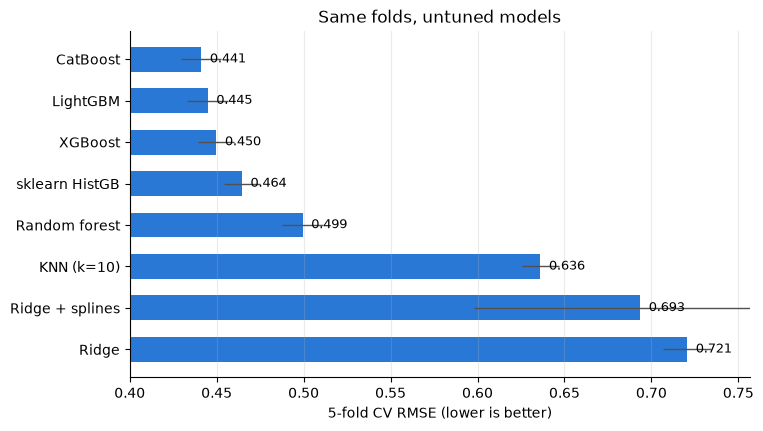

In [4]:
b = board.drop("Mean (baseline)").sort_values("CV RMSE", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(b.index, b["CV RMSE"], xerr=b["sd"], color=PALETTE[0], height=0.6, error_kw=dict(ecolor="#52514e", lw=1))
ax.set_xlim(0.4, b["CV RMSE"].max() * 1.05); ax.set_xlabel("5-fold CV RMSE (lower is better)")
ax.axvline(board.loc["Mean (baseline)", "CV RMSE"], color=GREY, ls="--")
for i, v in enumerate(b["CV RMSE"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_title("Same folds, untuned models"); ax.grid(axis="y", visible=False)
plt.show()

Typical pattern on tabular data: **boosting > random forest > KNN/linear**, with the three boosting libraries within noise of each other.
Differences smaller than the fold-to-fold `sd` aren't meaningful. (Ridge + splines has a large `sd` because one fold goes badly wrong: spline features on heavy-tailed inputs like `AveOccup` are fragile without clipping or log-transforms.)

## 2. Tuning with Optuna

Optuna does Bayesian-style search (TPE): it proposes parameters, learns which regions score well, and focuses there. Much more efficient than grid search when there are more than ~3 parameters.

Recipe for boosting:
1. Search with a fairly high `learning_rate` (0.1) for speed, using early stopping for the number of trees.
2. Search structure (`num_leaves`, `min_child_samples`), sampling, and regularisation.
3. For the final model, lower the learning rate (here 0.05) and scale the number of trees up accordingly.

In [5]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def cv_lgbm(params, n_splits=3):
    folds = KFold(n_splits, shuffle=True, random_state=SEED)
    scores, iters = [], []
    for tr, va in folds.split(X_train):
        m = lgb.LGBMRegressor(n_estimators=5000, learning_rate=0.1, random_state=SEED, verbose=-1, **params)
        m.fit(X_train.iloc[tr], y_train.iloc[tr], eval_set=[(X_train.iloc[va], y_train.iloc[va])],
              callbacks=[lgb.early_stopping(50, verbose=False)])
        scores.append(m.best_score_["valid_0"]["l2"] ** 0.5); iters.append(m.best_iteration_)
    return np.mean(scores), int(np.mean(iters))

def objective(trial):
    params = {
        "num_leaves": trial.suggest_int("num_leaves", 15, 255, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 200, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0), "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    }
    score, n_iter = cv_lgbm(params)
    trial.set_user_attr("n_estimators", n_iter)
    return score

t = time.time()
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=25)
default_score, _ = cv_lgbm({})
print(f"{len(study.trials)} trials in {time.time() - t:.0f}s")
print(f"default LightGBM CV RMSE: {default_score:.4f}")
print(f"tuned   LightGBM CV RMSE: {study.best_value:.4f}")
print("best params:", {k: round(v, 3) if isinstance(v, float) else v for k, v in study.best_params.items()},
      "| trees:", study.best_trial.user_attrs["n_estimators"])

25 trials in 65s
default LightGBM CV RMSE: 0.4563
tuned   LightGBM CV RMSE: 0.4508
best params: {'num_leaves': 200, 'min_child_samples': 23, 'subsample': 0.766, 'colsample_bytree': 0.566, 'reg_lambda': 0.1} | trees: 84


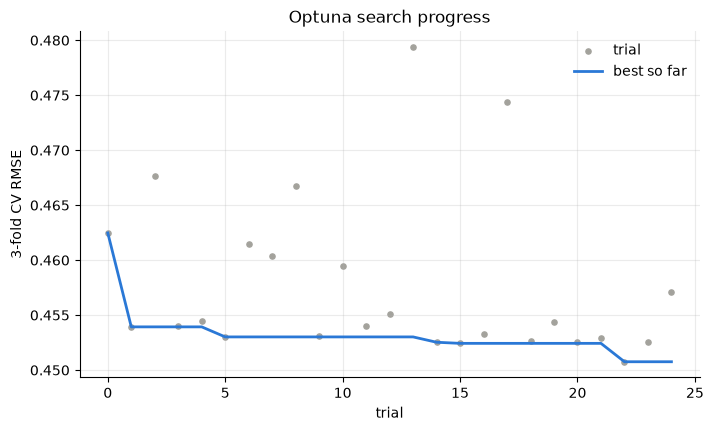

In [6]:
hist = study.trials_dataframe()
fig, ax = plt.subplots()
ax.scatter(hist["number"], hist["value"], s=14, color=GREY, label="trial")
ax.plot(hist["number"], hist["value"].cummin(), color=PALETTE[0], label="best so far")
ax.set_xlabel("trial"); ax.set_ylabel("3-fold CV RMSE"); ax.legend(); ax.set_title("Optuna search progress")
plt.show()

## 3. Final check on the untouched test set

In [7]:
best = dict(study.best_params, subsample_freq=1)
n_trees = int(study.best_trial.user_attrs["n_estimators"] * 2 * 1.2)    # half the learning rate -> ~2x trees; +20% for more data than a CV fold
final = lgb.LGBMRegressor(n_estimators=n_trees, learning_rate=0.05, random_state=SEED, verbose=-1, **best).fit(X_train, y_train)
default = lgb.LGBMRegressor(n_estimators=800, learning_rate=0.05, random_state=SEED, verbose=-1).fit(X_train, y_train)
rm = lambda m: np.sqrt(np.mean((y_test - m.predict(X_test)) ** 2))
print(f"test RMSE  default: {rm(default):.4f} | tuned: {rm(final):.4f}")

test RMSE  default: 0.4352 | tuned: 0.4339


## Advice
- **Selection bias:** the best of 25 CV scores is optimistic. The test set (or nested CV) gives the honest number.
- Spend tuning time in proportion to the gain. Hours of tuning for 0.5% is rarely worth it; a good feature is often worth 5%.
- Search on a log scale for scale-type parameters (`num_leaves`, regularisation, `min_child_samples`).
- Keep the CV folds fixed across all experiments so comparisons are paired.
- For a quick baseline, sklearn's `HistGradientBoostingRegressor` is a fine LightGBM-like option with no extra dependency.